# Financial Image Scans

This notebook reads scanned pages from a company financial report and turns them into a written
summary for a chosen reader.

The pages come from the ABN AMRO Q3 2024 report and are the two images supplied with the problem
statement:

- `balance_sheet.png`, the condensed consolidated statement of financial position
- `figures_at_a_glance.png`, nine bar charts covering five quarters each

The work happens in three model calls:

1. read the figures off the pages
2. write a summary for a chosen reader from those figures
3. read the charts

Splitting the reading step from the writing step is the main design choice here. A misread digit
shows up in the figure list, where it can be seen, instead of being buried inside a paragraph of
prose.

## 1. Install and key

In [1]:
!pip install langchain-openai==0.3.28
!pip install pillow==11.0.0
!pip install requests==2.32.3

The key is typed into a hidden prompt and kept in an environment variable, so the saved notebook
can be shared without carrying the credential in a cell.

In [2]:
from getpass import getpass
import os

os.environ['OPENAI_API_KEY'] = getpass('Enter Open AI API Key: ')

Enter Open AI API Key: ··········


## 2. Load the images

`load_images` accepts either a path on the local machine or a URL, opens each one with PIL, and
returns the images in a list. The list is what everything downstream works from.

In [3]:
import base64
import io

import requests
from PIL import Image


def load_images(sources):
    images = []

    for source in sources:
        if source.startswith('http://') or source.startswith('https://'):
            response = requests.get(source, timeout=30)
            response.raise_for_status()
            images.append(Image.open(io.BytesIO(response.content)))
        else:
            images.append(Image.open(source))

    return images

In [4]:
# Colab: run this cell to upload balance_sheet.png and figures_at_a_glance.png from the images folder.
from google.colab import files

uploaded = files.upload()

Saving balance_sheet.png to balance_sheet.png
Saving figures_at_a_glance.png to figures_at_a_glance.png


In [5]:
SOURCES = ['balance_sheet.png', 'figures_at_a_glance.png']
NAMES = ['balance_sheet', 'figures_at_a_glance']

pages = load_images(SOURCES)

for name, page in zip(NAMES, pages):
    print(name, page.size)

balance_sheet (642, 488)
figures_at_a_glance (637, 856)


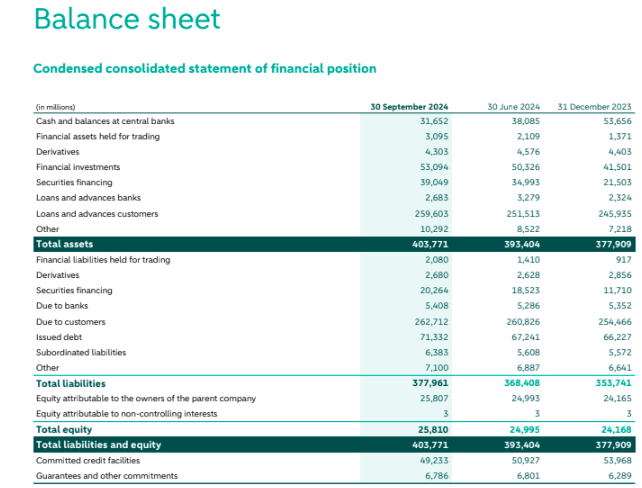

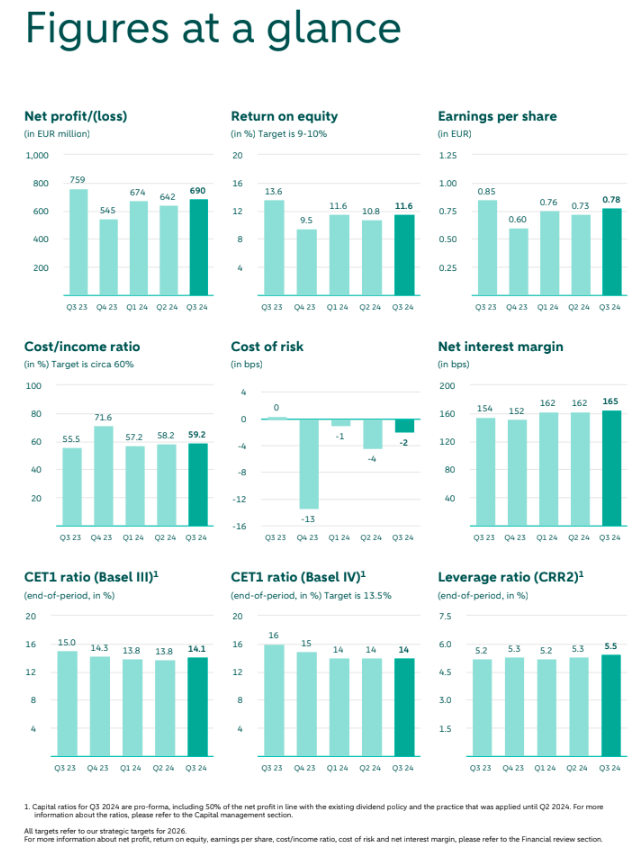

In [6]:
from IPython.display import display

for page in pages:
    display(page)

The model takes an image as a base64 data URL inside the message, so each page is encoded once and
reused across the calls.

In [7]:
def to_data_url(image):
    buffer = io.BytesIO()
    image.convert('RGB').save(buffer, format='PNG')
    encoded = base64.b64encode(buffer.getvalue()).decode()
    return f'data:image/png;base64,{encoded}'


def image_blocks(images):
    return [{'type': 'image_url', 'image_url': {'url': to_data_url(image)}} for image in images]


data_urls = {name: to_data_url(page) for name, page in zip(NAMES, pages)}

print('Encoded pages:', list(data_urls))

Encoded pages: ['balance_sheet', 'figures_at_a_glance']


## 3. Read the figures off the pages

Four things are doing the work in this section.

**A role and a rule in the system message.** The rule that matters is the one about missing
figures. Without it a model asked for revenue on a page that has no revenue line will supply a
number that looks right, and there is no way to tell that number apart from the printed ones.

**Tagged sections.** The instruction sits inside `<task>` tags. Tags mark where the instruction
stops more clearly than a blank line does, and later on they keep the report text from being read
as a new instruction.

**Reading separated from writing.** This call returns a flat list of figures and nothing else. No
sentences, no comparisons, no arithmetic. The summary in section 4 is written from that list.

**A schema for the output.** Asking for a Pydantic model gives back Python objects, so the figures
can be counted and checked in code instead of read off a wall of text.

In [9]:
from typing import List

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field

import langchain_core.globals
langchain_core.globals.set_verbose(False)

model = ChatOpenAI(model='gpt-4o-mini', temperature=0)

In [10]:
SYSTEM = """You read scanned pages from company financial reports and report what they show.

Work only from numbers and labels visible in the images.
If a figure is not in the images, write "not shown in the provided pages".
Never estimate a number that is not printed."""

In [11]:
class Metric(BaseModel):
    name: str = Field(description='The label as printed on the page')
    value: str = Field(description='The number as printed, including its unit')
    period: str = Field(description='The quarter or date the number belongs to')
    source_image: str = Field(description='balance_sheet or figures_at_a_glance')


class Extraction(BaseModel):
    metrics: List[Metric] = Field(description='Every figure printed on the pages')
    risks: List[str] = Field(description='Risks or cautions printed on the pages, empty if none are printed')

In [12]:
EXTRACTION_TASK = """<task>
List the figures printed on the attached pages.

For each figure give:
- name, the label as printed
- value, the number as printed with its unit
- period, the quarter or date it belongs to
- source_image, either balance_sheet or figures_at_a_glance

Then list any risk or caution printed on the pages. Return an empty list if none is printed.

Do not calculate anything. Do not combine figures. Do not add figures that are not printed.
</task>"""

In [15]:
import langchain_core.globals
langchain_core.globals.set_debug(False)
langchain_core.globals.set_llm_cache(None)

reader = model.with_structured_output(Extraction)

extraction = reader.invoke([
    SystemMessage(content=SYSTEM),
    HumanMessage(content=[{'type': 'text', 'text': EXTRACTION_TASK}] + image_blocks(pages)),
])

print('Figures read:', len(extraction.metrics))
print('Risks printed:', len(extraction.risks))

Figures read: 30
Risks printed: 0


In [16]:
for metric in extraction.metrics:
    print(f'{metric.name} | {metric.value} | {metric.period} | {metric.source_image}')

Cash and balances at central banks | 31,652 | 30 September 2024 | balance_sheet
Financial assets held for trading | 3,095 | 30 September 2024 | balance_sheet
Derivatives | 1,000 | 30 September 2024 | balance_sheet
Financial investments | 53,094 | 30 September 2024 | balance_sheet
Securities financing | 34,293 | 30 September 2024 | balance_sheet
Loans and advances banks | 2,683 | 30 September 2024 | balance_sheet
Loans and advances customers | 259,663 | 30 September 2024 | balance_sheet
Other | 10,292 | 30 September 2024 | balance_sheet
Total assets | 403,771 | 30 September 2024 | balance_sheet
Financial liabilities held for trading | 2,080 | 30 September 2024 | balance_sheet
Derivatives | 2,264 | 30 September 2024 | balance_sheet
Securities financing | 11,216 | 30 September 2024 | balance_sheet
Due to customers | 262,712 | 30 September 2024 | balance_sheet
Due to banks | 5,408 | 30 September 2024 | balance_sheet
Issued debt | 71,332 | 30 September 2024 | balance_sheet
Subordinated liab

Read that list against the images before going on. Anything wrong here is wrong in the summary
too, and this is the last point where it is easy to spot.

## 4. Write a summary for a chosen reader

The reader is a variable, not a separate prompt. One template takes an audience description from a
dictionary, so investor, analyst and auditor summaries come from the same instruction and stay
comparable.

The figure list from section 3 goes in under `<figures>`. The template also carries a short format
example taken from the problem statement. It is there to set the heading structure and the bullet
density. The prompt says to take the shape from the example and every number from `<figures>`.

In [17]:
AUDIENCES = {
    'investor': (
        'An investor holding or considering the stock. Wants profitability, per share figures, '
        'dividends, and how the latest quarter moved against the quarters shown before it.'
    ),
    'analyst': (
        'An equity analyst covering the bank. Wants what drove each change, the ratios, and the '
        'direction of travel across all five quarters on the charts.'
    ),
    'auditor': (
        'An auditor reviewing the accounts. Wants balance sheet composition, credit quality, any '
        'line that moved sharply between the periods shown, and what these pages do not cover.'
    ),
}

In [18]:
FORMAT_EXAMPLE = """Summary of ABN AMRO Bank Quarterly Report (Q3 2024)

Key Financial Metrics
- Net Profit: EUR 690 million, down from EUR 759 million in Q3 2023.
- Return on Equity: 11.6%, within the target of 9-10%.

Balance Sheet Highlights
- Total Assets: EUR 403.8 billion, an increase of EUR 10.4 billion from Q2 2024.
- Client Deposits: stable at EUR 224.5 billion.

Market Conditions and Outlook
- Management remains cautious about the Basel IV implementation."""

In [19]:
SUMMARY_TEMPLATE = """<task>
Write a summary of the report pages for the reader in <audience>.

Rules:
- Use only the figures listed in <figures>. Do not introduce a number from anywhere else.
- Group the figures under short headings and write them as bullets.
- Every bullet states a figure and what it means for this reader.
- Where the figures allow a comparison between periods, state the direction of the change.
- Close with three actions this reader should take, each tied to a figure above.
- If the reader asks about something the pages do not cover, write "not shown in the provided pages".

<format_example> shows heading structure and bullet density only. Take the shape from it and take
every number from <figures>.
</task>

<audience>
{audience}
</audience>

<figures>
{figures}
</figures>

<format_example>
{example}
</format_example>"""

In [20]:
def format_figures(extraction):
    lines = [f'- {m.name}: {m.value} ({m.period}, from {m.source_image})' for m in extraction.metrics]

    if extraction.risks:
        lines.append('')
        lines.extend(f'- risk printed on the page: {risk}' for risk in extraction.risks)

    return '\n'.join(lines)


def summarize_for(audience, extraction):
    prompt = SUMMARY_TEMPLATE.format(
        audience=AUDIENCES[audience],
        figures=format_figures(extraction),
        example=FORMAT_EXAMPLE,
    )

    response = model.invoke([
        SystemMessage(content=SYSTEM),
        HumanMessage(content=prompt),
    ])

    return response.content

In [21]:
print(summarize_for('investor', extraction))

Summary of Company Financial Report (Q3 2024)

Key Financial Metrics
- Net Profit: EUR 690 million, indicating profitability for the quarter.
- Earnings per Share: EUR 0.78, reflecting the company's earnings distributed to shareholders.
- Return on Equity: 11.6%, demonstrating effective use of equity to generate profit.

Balance Sheet Highlights
- Total Assets: EUR 403.8 billion, showing a solid asset base for the company.
- Total Liabilities: EUR 378.0 billion, indicating the company's obligations.
- Total Equity: EUR 25.8 billion, representing the net worth attributable to shareholders.

Operational Efficiency
- Cost/Income Ratio: 59.2%, suggesting a need for improved cost management compared to previous quarters.
- Net Interest Margin: 165 basis points, reflecting the profitability of the company's lending activities.

Regulatory Ratios
- CET1 Ratio (Basel III): 14.6%, indicating strong capital adequacy.
- Leverage Ratio (CRR2): 5.5%, showing a healthy balance between debt and equit

In [22]:
print(summarize_for('analyst', extraction))

Summary of Bank Financial Report (30 September 2024)

Key Financial Metrics
- Net Profit: EUR 690 million, indicating profitability for Q3 2024.
- Return on Equity: 11.6%, suggesting effective use of equity to generate profit.

Balance Sheet Highlights
- Total Assets: EUR 403.8 billion, reflecting a solid asset base.
- Total Liabilities: EUR 378.0 billion, showing a strong liability management.
- Total Equity: EUR 25.8 billion, indicating a stable equity position.

Asset Composition
- Cash and Balances at Central Banks: EUR 31.7 billion, providing liquidity support.
- Loans and Advances to Customers: EUR 259.7 billion, a key revenue-generating asset.
- Financial Investments: EUR 53.1 billion, contributing to the bank's investment strategy.

Liability Composition
- Due to Customers: EUR 262.7 billion, representing the bank's primary funding source.
- Issued Debt: EUR 71.3 billion, indicating reliance on debt financing.

Capital Ratios
- CET1 Ratio (Basel III): 14.6%, demonstrating stron

In [23]:
print(summarize_for('auditor', extraction))

Summary of Company Financial Report (30 September 2024)

Key Financial Metrics
- Net Profit: 690, indicating profitability for Q3 2024.
- Return on Equity: 11.6%, suggesting effective use of equity to generate profit.

Balance Sheet Highlights
- Total Assets: 403,771, reflecting the overall size and resources of the company.
- Total Liabilities: 377,961, showing the obligations the company must meet.
- Total Equity: 25,810, representing the net worth attributable to shareholders.

Credit Quality Indicators
- Loans and Advances to Customers: 259,663, indicating a strong lending position.
- CET1 Ratio (Basel III): 14.6, demonstrating solid capital adequacy.
- CET1 Ratio (Basel IV): 14.4, indicating compliance with future regulatory requirements.

Sharp Movements
- Financial Liabilities Held for Trading: 2,080, a notable figure that may indicate changes in trading activities.
- Due to Customers: 262,712, reflecting a significant reliance on customer deposits.

Actions for the Auditor
1. R

## 5. Read the charts

The charts page gets its own call because the ask is specific to it. Only that image goes in, so
the balance sheet table cannot pull the answer off course.

The instruction that earns its place is the last one. Every bar on this page carries a printed data
label, and a model left to judge a bar by its height will drift. Telling it to read the label
removes the guessing.

In [24]:
CHART_TASK = """<task>
Read each chart on this page. For each one report:
- the metric name and its unit
- the value for every bar, in the order shown
- the direction of the trend across the quarters
- whether the latest value sits inside or outside any target printed on the chart

Read the printed data labels. Do not judge values by bar height.
</task>"""

charts = pages[NAMES.index('figures_at_a_glance')]

response = model.invoke([
    SystemMessage(content=SYSTEM),
    HumanMessage(content=[{'type': 'text', 'text': CHART_TASK}] + image_blocks([charts])),
])

print(response.content)

Here’s the analysis of the charts on the page:

### 1. Net profit/(loss)
- **Metric Name and Unit**: Net profit/(loss) (in EUR million)
- **Values**: 
  - Q3 23: 759
  - Q4 23: 674
  - Q1 24: 642
  - Q2 24: 690
- **Trend Direction**: Fluctuating, with a decrease from Q3 23 to Q4 23, then a decrease to Q1 24, followed by an increase in Q2 24.
- **Latest Value Target Status**: The latest value (690) is outside the target (not specified in the chart).

### 2. Return on equity
- **Metric Name and Unit**: Return on equity (in %)
- **Values**: 
  - Q3 23: 13.6
  - Q4 23: 9.5
  - Q1 24: 11.6
  - Q2 24: 10.8
- **Trend Direction**: Fluctuating, with a decrease from Q3 23 to Q4 23, then an increase to Q1 24, followed by a decrease in Q2 24.
- **Latest Value Target Status**: The latest value (11.6) is inside the target (9-10%).

### 3. Earnings per share
- **Metric Name and Unit**: Earnings per share (in EUR)
- **Values**: 
  - Q3 23: 0.85
  - Q4 23: 0.60
  - Q1 24: 0.76
  - Q2 24: 0.78
- **Trend

## 6. Notes and limits

- The figures come from a model reading an image. Check them against the source pages before using
  them for anything that matters.
- A low resolution or skewed scan produces wrong digits, and the wrong digits look exactly like the
  right ones in the output.
- The format example in section 4 is from the same report as the images. It is there for shape. If
  the notebook is pointed at a different company, replace the example with one from that report or
  the headings will not fit.
- Two pages of one quarter of one bank is not enough for a view on the business. The notebook shows
  the method, not a finished piece of analysis.
- The charts call reads printed labels. A chart with no data labels falls back to bar height, which
  is where the errors start.